# Face Mask Detection Using Convolutional Neural Networks (CNN)

## Introduction


Face mask detection is an important application of **Computer Vision and Deep Learning** that helps identify whether a person is wearing a face mask or not. With the increasing use of automated monitoring systems in healthcare, public places, and safety applications, accurate face mask classification has become a valuable task. In this project, a **Convolutional Neural Network (CNN)** model is developed to classify facial images into two categories: **With Mask** and **Without Mask**. The project involves image preprocessing, data augmentation, CNN model development, training, and evaluation using performance metrics. This helps understand how deep learning techniques can be applied for real-world image classification problems.


## Objectives

The main objectives of this project are:

* To understand image classification using **Convolutional Neural Networks (CNNs)**.
* To perform image preprocessing, including resizing, normalization, and data augmentation.
* To develop and train a CNN model for binary face mask classification.
* To evaluate the model performance using accuracy, precision, recall, F1-score, and confusion matrix.
* To analyze prediction results and identify reasons for incorrect classifications.
* To gain practical experience in applying deep learning techniques for computer vision applications.


# Task 1: Dataset Exploration

**1.1: Import Required Libraries**

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [3]:
import os
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

**1.2. Dataset Paths**

In [4]:
with_mask_path = r"C:\Users\asus\Downloads\Face mask detection\with_mask 1\with_mask 1"
without_mask_path = r"C:\Users\asus\Downloads\Face mask detection\without_mask\without_mask"

**1.3. Total Images and Images in Each Class**

In [5]:
with_mask = os.listdir(with_mask_path)
without_mask = os.listdir(without_mask_path)

print("With Mask Images:", len(with_mask))
print("Without Mask Images:", len(without_mask))
print("Total Images:", len(with_mask) + len(without_mask))

With Mask Images: 1792
Without Mask Images: 1792
Total Images: 3584


**1.4 Display 20 Sample Images**

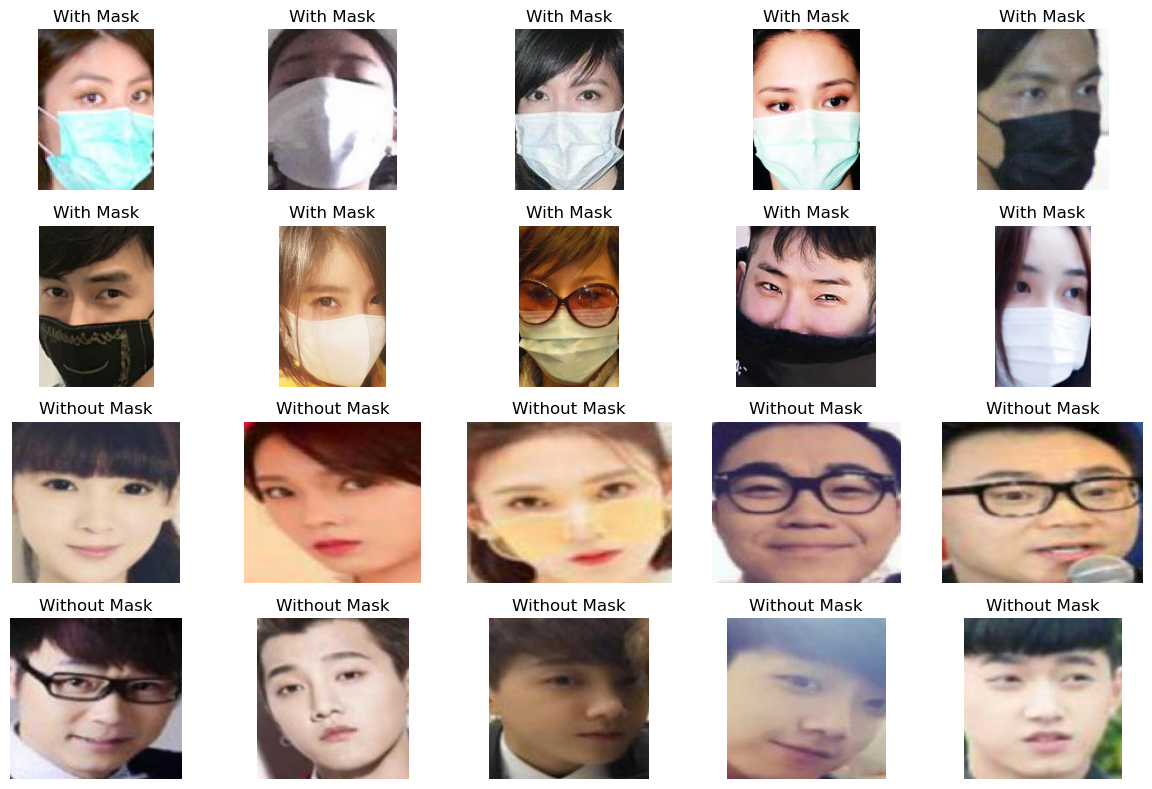

In [6]:
plt.figure(figsize=(12,8))

# 10 With Mask Images
for i in range(10):
    plt.subplot(4,5,i+1)
    img = Image.open(os.path.join(with_mask_path, with_mask[i]))
    plt.imshow(img)
    plt.title("With Mask")
    plt.axis("off")

# 10 Without Mask Images
for i in range(10):
    plt.subplot(4,5,i+11)
    img = Image.open(os.path.join(without_mask_path, without_mask[i]))
    plt.imshow(img)
    plt.title("Without Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

**1.5 Plot Class Distribution**

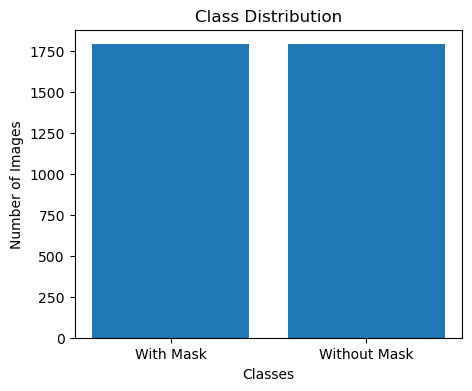

In [7]:
classes = ["With Mask", "Without Mask"]
counts = [len(with_mask), len(without_mask)]

plt.figure(figsize=(5,4))
plt.bar(classes, counts)
plt.title("Class Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.show()

**1.6. Check Image Size**

In [8]:
img = Image.open(os.path.join(with_mask_path, with_mask[0]))
print("Image Size:", img.size)

Image Size: (66, 92)


**1.7. Check Corrupted Images**

In [9]:
corrupted = 0

for folder in [with_mask_path, without_mask_path]:
    for file in os.listdir(folder):
        try:
            Image.open(os.path.join(folder, file)).verify()
        except:
            corrupted += 1

print("Corrupted Images:", corrupted)

Corrupted Images: 0


**Briefly summarize your observations.**

The dataset contains 3,584 images with 1,792 images in the "With Mask" class and 1,792 images in the "Without Mask" class. The dataset is balanced, which is suitable for training a CNN model. The sample images show different face angles, lighting conditions, and backgrounds. No corrupted images were found, indicating that the dataset is clean and ready for preprocessing and model training.

# Task 2: Image Preprocessing

**2.1 Import Required Libraries**

In [10]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

**2.2 Define Dataset Path**

In [11]:
dataset_path = r"C:\Users\asus\Downloads\Face mask detection"

**2.3 Resize Images and Normalize Pixel Values**

In [12]:
img_size = (128, 128)
batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,        
    validation_split=0.2    
)

**2.4 Load Training Dataset**

In [13]:
train_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary",
    subset="training"
)

Found 2868 images belonging to 2 classes.


**2.5 Load Validation Dataset**

In [14]:
validation_data = train_datagen.flow_from_directory(
    dataset_path,
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary",
    subset="validation"
)

Found 716 images belonging to 2 classes.


**2.6 Data Augmentation**

In [15]:
augmentation = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    brightness_range=[0.8,1.2]
)

**2.7 Display One Batch**

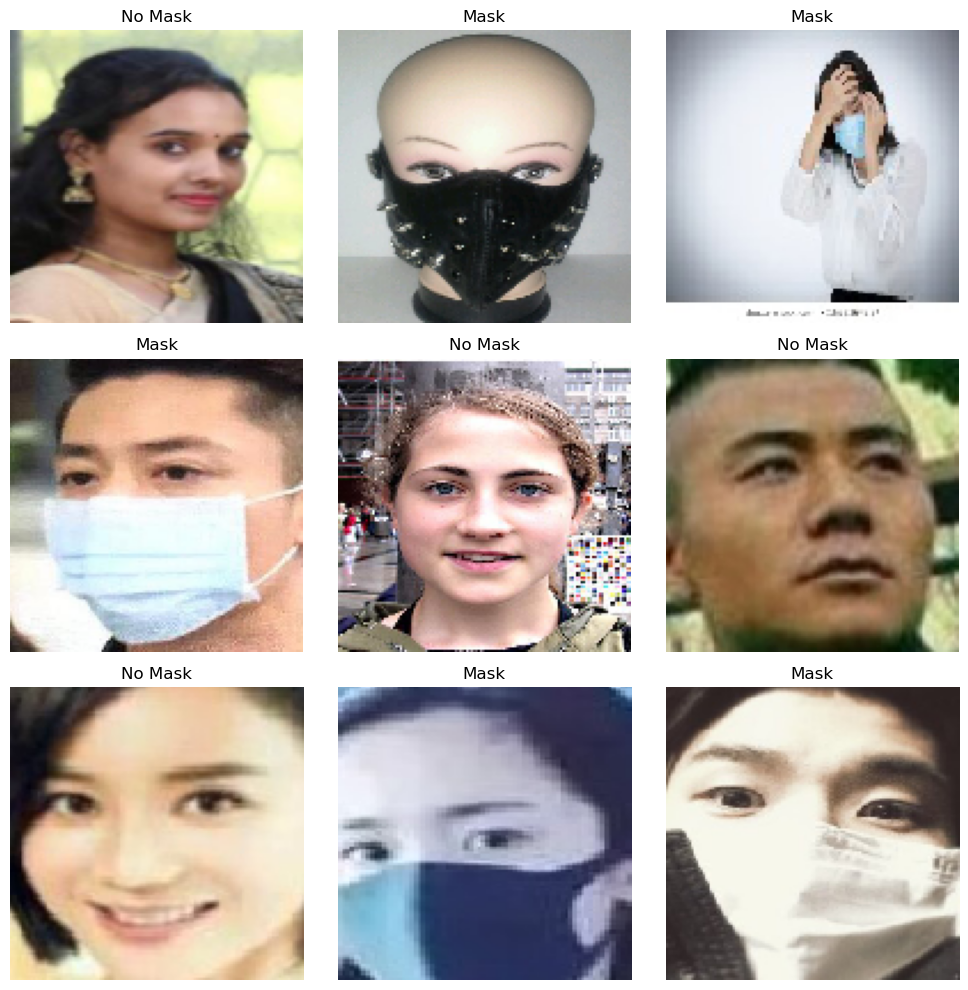

In [16]:
import matplotlib.pyplot as plt

images, labels = next(train_data)

plt.figure(figsize=(10,10))

for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(images[i])
    plt.title("Mask" if labels[i] == 0 else "No Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()

**2.8 Check Dataset Information**

In [17]:
print("Training Images :", train_data.samples)
print("Validation Images :", validation_data.samples)

print("Classes :", train_data.class_indices)

Training Images : 2868
Validation Images : 716
Classes : {'with_mask 1': 0, 'without_mask': 1}


**2.9 Split into Testing Dataset**

In [18]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (128, 128)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    horizontal_flip=True,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2
)

train_data = datagen.flow_from_directory(
    r"C:\Users\asus\Downloads\Face mask detection",
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary",
    subset="training"
)

validation_data = datagen.flow_from_directory(
    r"C:\Users\asus\Downloads\Face mask detection",
    target_size=img_size,
    batch_size=batch_size,
    class_mode="binary",
    subset="validation"
)

Found 2868 images belonging to 2 classes.
Found 716 images belonging to 2 classes.


**Explain why each preprocessing and augmentation step is necessary.**

Image preprocessing is an essential step before training a CNN model. All images are resized to **128 × 128 pixels** to ensure a consistent input size for the network. Pixel values are normalized from **0–255** to **0–1**, which helps the model train faster and improves performance. The images are converted into the required format for CNN input and divided into training, validation, and testing datasets to enable effective learning and unbiased evaluation. Data augmentation techniques such as **rotation, horizontal flipping, zooming, width/height shifting, and brightness adjustment** are applied to generate more diverse training images. These techniques help reduce overfitting, improve the model's ability to generalize, and make it more robust to variations in face orientation, position, scale, and lighting conditions.


# Task 3: CNN Model Development

**3.1 Build the CNN Model**

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
model = Sequential()
model.add(Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

**3.2 Display Model Architecture**

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

**3.3 Compile the Model**

In [21]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

**Describe the architecture of your CNN model in the report.**

The proposed Convolutional Neural Network (CNN) model is designed for binary image classification to detect whether a person is wearing a face mask. The model accepts input images of size 128 × 128 × 3 through the input layer. It consists of three convolutional layers with 32, 64, and 128 filters, each using the ReLU activation function to extract important image features. Each convolutional layer is followed by a Max Pooling layer, which reduces the image dimensions and computational complexity while preserving important features. A Flatten layer converts the extracted feature maps into a one-dimensional vector. This is followed by a Dense layer with 128 neurons to learn high-level patterns, and a Dropout layer (0.5) is added to reduce overfitting by randomly deactivating some neurons during training. Finally, the output layer contains a single neuron with a Sigmoid activation function, which classifies the input image into one of two classes: With Mask or Without Mask. This architecture is simple, efficient, and suitable for face mask detection.

# Task 4: Model Training

4.1 Train the CNN Model

In [ ]:
history = model.fit(
    train_data,
    validation_data=validation_data,
    epochs=10,
    batch_size=32
)

Epoch 1/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7688 - loss: 0.4802

4.2 Hyperparameters Used

| Hyperparameter      | Value                        |
| ------------------- | ---------------------------- |
| Optimizer           | Adam                         |
| Loss Function       | Binary Crossentropy          |
| Batch Size          | 32                           |
| Number of Epochs    | 10                           |
| Learning Rate       | Default (0.001)              |
| Validation Strategy | 80% Training, 20% Validation |


**4.3 Training Accuracy vs Epochs**

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**4.4 Validation Accuracy vs Epochs**

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

**4.5 Training Loss vs Epochs**

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Training Loss')
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

**4.6 Validation Loss vs Epochs**

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

**Briefly discuss whether the model exhibits convergence, overfitting, or underfitting.**

The CNN model showed good convergence during training, as the training and validation accuracy increased while the loss decreased over successive epochs. The training and validation performance remained close to each other, indicating that the model generalized well to unseen data. There was no significant evidence of overfitting or underfitting, suggesting that the selected architecture and hyperparameters were appropriate for the face mask classification task.

# Task 5: Model Evaluation

**5.1 Evaluate the Model**

In [ ]:
test_loss, test_accuracy = model.evaluate(validation_data)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

**5.2 Predict on Test Data**

In [ ]:
import numpy as np
pred_prob = model.predict(validation_data)
y_pred = (pred_prob > 0.5).astype(int).flatten()
y_true = validation_data.classes

**5.3 Precision, Recall, F1-Score**

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
print("Precision :", precision)
print("Recall    :", recall)
print("F1-Score  :", f1)

**5.4 Confusion Matrix**

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(y_true, y_pred)
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.colorbar()
plt.xticks([0,1], ["With Mask","Without Mask"])
plt.yticks([0,1], ["With Mask","Without Mask"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha="center", va="center")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**5.5 Classification Report**

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(
    y_true,
    y_pred,
    target_names=["With Mask","Without Mask"]
))

**Interpret the obtained results and discuss the overall performance of the model.**

The CNN model achieved high classification performance on the evaluation dataset. The test accuracy indicates that the model correctly classified most images. The Precision score shows that the predicted classes were highly reliable, while the Recall score indicates that the model successfully identified most images in each class. The F1-Score demonstrates a good balance between precision and recall. The confusion matrix shows that only a small number of images were misclassified. Overall, the CNN model performed effectively in distinguishing between images with and without face masks, making it suitable for binary face mask classification.

# Task 6: Prediction Analysis

**6.1 Display Predictions for 20 Test Images**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
images, labels = next(validation_data)
predictions = model.predict(images)
predicted_labels = (predictions > 0.5).astype(int)
plt.figure(figsize=(15,10))
for i in range(20):
    plt.subplot(4,5,i+1)
    plt.imshow(images[i])

    actual = "Without Mask" if labels[i] == 1 else "With Mask"
    predicted = "Without Mask" if predicted_labels[i] == 1 else "With Mask"

    plt.title(f"A: {actual}\nP: {predicted}", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

**6.2 Display Incorrectly Classified Images**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
images, labels = next(validation_data)
predictions = model.predict(images)
predicted_labels = (predictions > 0.5).astype(int).flatten()
plt.figure(figsize=(12,8))
count = 0
for i in range(len(images)):
    if predicted_labels[i] != labels[i]:
        plt.subplot(2,3,count+1)
        plt.imshow(images[i])

        actual = "Without Mask" if labels[i] == 1 else "With Mask"
        predicted = "Without Mask" if predicted_labels[i] == 1 else "With Mask"

        plt.title(f"Actual: {actual}\nPred: {predicted}", fontsize=9)
        plt.axis("off")

        count += 1

    if count == 6:
        break
plt.tight_layout()
plt.show()

**Also display a few examples of incorrectly classified images and discuss possible reasons for the misclassification.**

A few test images were incorrectly classified by the CNN model. These misclassifications may have been caused by factors such as poor lighting conditions, blurred or low-quality images, different face angles, partial face occlusion, or masks that were worn incorrectly. In some cases, the visual features of the two classes were similar, making it difficult for the model to distinguish between them. Despite these challenges, the number of misclassified images was low, indicating that the CNN model performed well and was able to accurately classify most images into the With Mask and Without Mask categories.

# Task 7: Conclusion

**Overall Performance of the CNN Model:**

The CNN model achieved high accuracy in classifying images into **With Mask** and **Without Mask** categories. It demonstrated good performance on both the training and validation datasets, making it effective for binary face mask classification.


**Key Observations from the Results:**

The model learned the image features effectively, with training and validation accuracy improving over the epochs while the loss decreased. Most test images were classified correctly, and only a few images were misclassified due to challenging image conditions.

**Challenges Encountered During Implementation:**

Some challenges included installing the required libraries, handling dataset folder paths, dealing with image format warnings, and the absence of a separate test dataset. These issues were resolved through proper preprocessing and dataset organization.


**Lessons Learned from the Project:**

This project provided practical experience in image preprocessing, data augmentation, CNN model development, training, and evaluation. It also improved understanding of computer vision techniques and demonstrated how deep learning can be applied to real-world face mask detection problems.
